In [1]:
# hafta 12: kendi GPT-2'mizi gercek veride egitmek ve OpenAI'nin modeliyle ayni testte olcmek

#### son hafta. hafta 10'da GPT-2'yi yazdik, hafta 11'de hizlandirdik. simdi gercek veride egitip olcuyoruz.
# plan:
#   task 1: FineWeb-Edu'dan 210 milyon token indirip dosyalara boluyoruz, data loader bu dosyalardan okuyor. ilk dosya dogrulama icin ayrildi.
#   task 2: egitim sirasinda belli araliklarla val loss olcuyoruz ve modelden ayni baslangiclarla kisa metin urettiriyoruz.
#   task 3: hafta 11'in hizlandirilmis modelini colab A100'de ~197 milyon token egitiyoruz.
#   task 4: HellaSwag'i once kendi modelimizde, sonra OpenAI'nin GPT-2 agirliklarinda ayni kodla kosuyoruz.
# ciktilardaki butun sureler A100'e ait.

In [2]:
%pip install -q tiktoken datasets transformers

In [3]:
import glob, json, math, os, time, gc
os.environ['HF_HUB_DISABLE_PROGRESS_BARS'] = '1'
import numpy as np
import torch
import torch.nn as nn
from contextlib import nullcontext
from dataclasses import dataclass
from torch.nn import functional as F
import matplotlib.pyplot as plt
import tiktoken

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device :', device)
print('torch  :', torch.__version__)
if device == 'cuda':
    cap = torch.cuda.get_device_capability()
    print('gpu    :', torch.cuda.get_device_name(0), f'(compute capability {cap[0]}.{cap[1]})')
    print('bellek :', f'{torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')
    bf16_var = cap >= (8, 0)
else:
    bf16_var = False
amp_dtype = torch.bfloat16 if bf16_var else torch.float16
print('autocast:', amp_dtype)

enc = tiktoken.get_encoding('gpt2')
eot = enc._special_tokens['<|endoftext|>']

def senkron():
    if device == 'cuda':
        torch.cuda.synchronize()

device : cuda
torch  : 2.14.1+cu130
gpu    : NVIDIA A100-SXM4-40GB (compute capability 8.0)
bellek : 42.4 GB
autocast: torch.bfloat16


## task 1
Veriyi hazırla. FineWeb-Edu'dan küçük bir parça (birkaç on milyon token yeterli) ya da kendi Türkçe metnini GPT-2 tokenizer'ıyla token'la. Token'ları dosyalara böl ve data loader'ını bu dosyalardan okuyacak hâle getir. Bir dosyayı doğrulama için ayır. (3:10:21 - 3:23:10)

In [4]:
DATA_DIR = 'fineweb_edu'
SHARD_TOKEN = 10_000_000       # dosya basina token
N_SHARD = 21                   # 1 val + 20 train = 210M token

os.makedirs(DATA_DIR, exist_ok=True)

def shard_yaz(no, dizi):
    # token'lar uint16: en buyuk id 50256, 2 byte'a sigiyor. dosya basina 20 MB
    assert dizi.max() < 2 ** 16
    np.save(os.path.join(DATA_DIR, f'shard_{no:03d}.npy'), dizi)

if len(glob.glob(f'{DATA_DIR}/shard_*.npy')) < N_SHARD:
    from datasets import load_dataset
    t0 = time.time()
    ds = load_dataset('HuggingFaceFW/fineweb-edu', split='train', streaming=True)
    tampon = np.empty(SHARD_TOKEN, dtype=np.uint16)
    dolu, shard_no, n_doc = 0, 0, 0
    parca = []

    def parcayi_isle(metinler):
        global dolu, shard_no, n_doc
        for tok in enc.encode_ordinary_batch(metinler, num_threads=os.cpu_count()):
            n_doc += 1
            tok = np.array([eot] + tok, dtype=np.uint16)   # her dokumanin basinda <|endoftext|>: model dokuman sinirini goruyor
            while len(tok) > 0 and shard_no < N_SHARD:
                sigan = min(len(tok), SHARD_TOKEN - dolu)
                tampon[dolu:dolu + sigan] = tok[:sigan]
                dolu += sigan
                tok = tok[sigan:]
                if dolu == SHARD_TOKEN:
                    shard_yaz(shard_no, tampon)
                    print(f'shard {shard_no:03d} yazildi | {n_doc:,d} dokuman | {time.time() - t0:.0f} sn', flush=True)
                    shard_no += 1
                    dolu = 0

    for satir in ds:
        parca.append(satir['text'])
        if len(parca) == 1000:
            parcayi_isle(parca)
            parca = []
            if shard_no == N_SHARD:
                break
    print(f'toplam: {shard_no} dosya, {shard_no * SHARD_TOKEN:,d} token, {n_doc:,d} dokuman, {time.time() - t0:.0f} sn')

dosyalar = sorted(glob.glob(f'{DATA_DIR}/shard_*.npy'))
print('dosyalar:', [os.path.basename(d) for d in dosyalar])
ornek = np.load(dosyalar[0])
print('ilk dosya:', ornek.shape, ornek.dtype, f'{os.path.getsize(dosyalar[0]) / 1e6:.0f} MB')
print('ilk 80 token metin olarak:')
print(enc.decode(ornek[:80].tolist()))

Resolving data files:   0%|          | 0/2410 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/2410 [00:00<?, ?it/s]

shard 000 yazildi | 9,717 dokuman | 18 sn


shard 001 yazildi | 19,225 dokuman | 23 sn


shard 002 yazildi | 28,626 dokuman | 28 sn


shard 003 yazildi | 38,028 dokuman | 34 sn


... (14 outputs left out)

shard 018 yazildi | 179,515 dokuman | 98 sn


shard 019 yazildi | 189,293 dokuman | 102 sn


shard 020 yazildi | 198,749 dokuman | 107 sn


toplam: 21 dosya, 210,000,000 token, 199,000 dokuman, 107 sn
dosyalar: ['shard_000.npy', 'shard_001.npy', 'shard_002.npy', 'shard_003.npy', 'shard_004.npy', 'shard_005.npy', 'shard_006.npy', 'shard_007.npy', 'shard_008.npy', 'shard_009.npy', 'shard_010.npy', 'shard_011.npy', 'shard_012.npy', 'shard_013.npy', 'shard_014.npy', 'shard_015.npy', 'shard_016.npy', 'shard_017.npy', 'shard_018.npy', 'shard_019.npy', 'shard_020.npy']
ilk dosya: (10000000,) uint16 20 MB
ilk 80 token metin olarak:
<|endoftext|>No. 24; Updated March 2011
Click here to download and print a PDF version of this document.
Parents are usually the first to recognize that their child has a problem with emotions or behavior. Still, the decision to seek professional help can be difficult and painful for a parent. The first step is to gently try to talk to the child. An honest open talk about feelings can often help


In [ ]:
#### FineWeb-Edu: web'den toplanmis, egitim degeri yuksek diye secilmis ingilizce sayfalar. tamamini indirmedik, streaming ile bastan okuyup yeterince token olunca durduk.
# 199.000 dokuman, 210 milyon token, 21 dosya, 107 saniye (indirme + token'lama beraber).
# her dosya 10 milyon token, uint16 olarak 20 MB. en buyuk token id 50.256, 2 byte'a sigiyor.
# her dokumanin basina <|endoftext|> koyduk: model bir metnin bitip digerinin basladigini boylece goruyor.
# neden dosyalara boluyoruz: hepsi bellege sigmayabilir, bir dosya bitince digerine geciyoruz. karpathy'nin 10 milyar token'lik egitimiyle ayni yapi, sadece sayi kucuk.

In [6]:
def load_tokens(yol):
    return torch.tensor(np.load(yol).astype(np.int64), dtype=torch.long)

class DataLoaderLite:
    def __init__(self, B, T, split):
        assert split in ('train', 'val')
        self.B, self.T = B, T
        dosyalar = sorted(glob.glob(f'{DATA_DIR}/shard_*.npy'))
        self.dosyalar = dosyalar[:1] if split == 'val' else dosyalar[1:]   # ilk dosya val, geri kalani train
        self.reset()

    def reset(self):
        self.dosya_no = 0
        self.tokens = load_tokens(self.dosyalar[0])
        self.konum = 0

    def next_batch(self):
        B, T = self.B, self.T
        buf = self.tokens[self.konum: self.konum + B * T + 1]
        x = buf[:-1].view(B, T)
        y = buf[1:].view(B, T)
        self.konum += B * T
        if self.konum + B * T + 1 > len(self.tokens):                     # dosya bitti, sonrakine gec
            self.dosya_no = (self.dosya_no + 1) % len(self.dosyalar)
            self.tokens = load_tokens(self.dosyalar[self.dosya_no])
            self.konum = 0
        return x.to(device), y.to(device)

deneme = DataLoaderLite(4, 1024, 'train')
x, y = deneme.next_batch()
print('train dosya sayisi:', len(deneme.dosyalar), '| x:', x.shape, '| y:', y.shape)
print('y, x\'in bir kaydirilmis hali mi:', (x[0, 1:] == y[0, :-1]).all().item())
del deneme

train dosya sayisi: 20 | x: torch.Size([4, 1024]) | y: torch.Size([4, 1024])
y, x'in bir kaydirilmis hali mi: True


In [ ]:
#### loader artik metnin tamamini degil, dosyalari okuyor. ilk dosya (10 milyon token) dogrulama, kalan 20 dosya (200 milyon token) egitim icin.
# bir dosya bitince sonrakine geciyor, hepsi bitince basa donuyor. x ve y hala bir token kaydirilmis (ciktida True).
# val dosyasi egitime hic girmiyor. yani val loss modelin gercekten gormedigi metindeki loss.

In [8]:
@dataclass
class GPTConfig:
    block_size: int = 1024
    vocab_size: int = 50304      # hafta 11: 50.257 yerine 50.304 (2'nin kuvvetlerine bolunuyor, gpu'da hizli)
    n_layer: int = 12
    n_head: int = 12
    n_embd: int = 768

class CausalSelfAttention(nn.Module):
    def __init__(self, config):
        super().__init__()
        assert config.n_embd % config.n_head == 0
        self.n_head, self.n_embd = config.n_head, config.n_embd
        self.c_attn = nn.Linear(config.n_embd, 3 * config.n_embd)
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)
        self.c_proj.SCALE_INIT = 1

    def forward(self, x):
        B, T, C = x.shape
        hs = C // self.n_head
        q, k, v = self.c_attn(x).split(self.n_embd, dim=2)
        q = q.view(B, T, self.n_head, hs).transpose(1, 2)
        k = k.view(B, T, self.n_head, hs).transpose(1, 2)
        v = v.view(B, T, self.n_head, hs).transpose(1, 2)
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True)    # flash attention
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        return self.c_proj(y)

class MLP(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.c_fc = nn.Linear(config.n_embd, 4 * config.n_embd)
        self.gelu = nn.GELU(approximate='tanh')
        self.c_proj = nn.Linear(4 * config.n_embd, config.n_embd)
        self.c_proj.SCALE_INIT = 1

    def forward(self, x):
        return self.c_proj(self.gelu(self.c_fc(x)))

class Block(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self, x):
        x = x + self.attn(self.ln_1(x))
        x = x + self.mlp(self.ln_2(x))
        return x

class GPT(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.config = config
        self.transformer = nn.ModuleDict(dict(
            wte=nn.Embedding(config.vocab_size, config.n_embd),
            wpe=nn.Embedding(config.block_size, config.n_embd),
            h=nn.ModuleList([Block(config) for _ in range(config.n_layer)]),
            ln_f=nn.LayerNorm(config.n_embd),
        ))
        self.lm_head = nn.Linear(config.n_embd, config.vocab_size, bias=False)
        self.transformer.wte.weight = self.lm_head.weight              # weight tying
        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            std = 0.02
            if hasattr(module, 'SCALE_INIT'):
                std *= (2 * self.config.n_layer) ** -0.5
            torch.nn.init.normal_(module.weight, mean=0.0, std=std)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device)
        x = self.transformer.wte(idx) + self.transformer.wpe(pos)
        for block in self.transformer.h:
            x = block(x)
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

def configure_optimizers(model, weight_decay, learning_rate):
    params = {n: p for n, p in model.named_parameters() if p.requires_grad}
    decay = [p for p in params.values() if p.dim() >= 2]
    nodecay = [p for p in params.values() if p.dim() < 2]
    groups = [{'params': decay, 'weight_decay': weight_decay}, {'params': nodecay, 'weight_decay': 0.0}]
    return torch.optim.AdamW(groups, lr=learning_rate, betas=(0.9, 0.95), eps=1e-8, fused=(device == 'cuda'))

def get_lr(it, max_lr, min_lr, warmup_steps, max_steps):
    if it < warmup_steps:
        return max_lr * (it + 1) / warmup_steps
    if it > max_steps:
        return min_lr
    oran = (it - warmup_steps) / (max_steps - warmup_steps)
    coeff = 0.5 * (1.0 + math.cos(math.pi * oran))
    return min_lr + coeff * (max_lr - min_lr)

print('model:', f'{sum(p.numel() for p in GPT(GPTConfig()).parameters()):,d}', 'parametre')

model: 124,475,904 parametre


## task 2
Doğrulama loss'unu ve örnekleri ekle. Eğitim sırasında belli aralıklarla doğrulama loss'unu ölç ve modelden kısa bir metin ürettir. Train ve val loss'u aynı grafikte çiz. (3:23:10 - 3:28:23)

In [9]:
ctx = torch.autocast(device_type=device, dtype=amp_dtype) if device == 'cuda' else nullcontext()

VAL_BATCH = 12          # her olcumde 12 batch: 12 x 32768 = ~393 bin token
BASLANGICLAR = ["Hello, I'm a language model,",
                "The Earth orbits the",
                "In mathematics, a prime number is"]

@torch.no_grad()
def val_olc(m, loader):
    loader.reset()      # her seferinde ayni val parcasi: olcumler birbiriyle kiyaslanabilsin
    toplam = 0.0
    for _ in range(VAL_BATCH):
        x, y = loader.next_batch()
        with ctx:
            _, loss = m(x, y)
        toplam += loss.item() / VAL_BATCH
    return toplam

@torch.no_grad()
def uret(m, baslangic, n_token=40, top_k=50, seed=42):
    # ayni seed: egitim ilerledikce metin farkliligi modelden gelsin, rastgelelikten degil
    g = torch.Generator(device=device).manual_seed(seed)
    idx = torch.tensor([enc.encode(baslangic)], device=device)
    for _ in range(n_token):
        with ctx:
            logits, _ = m(idx[:, -m.config.block_size:])
        son = logits[:, -1, :50257].float()     # 50257 sonrasi bos vocab, token karsiligi yok
        olas = F.softmax(son, dim=-1)
        v, ix = torch.topk(olas, top_k, dim=-1)
        sec = torch.multinomial(v, 1, generator=g)
        idx = torch.cat([idx, ix.gather(-1, sec)], dim=1)
    return enc.decode(idx[0].tolist())

In [ ]:
#### val_olc: val loss'u her seferinde ayni parcada olcuyoruz (12 batch, 393 bin token). parca degisseydi egrideki dususun bir kismi sadece farkli metin yuzunden olurdu.
# uret: top-k 50 ile ornekleme. seed sabit, yani adimlar arasindaki fark modelden geliyor.
# vocab 50.304 oldugu icin 47 id'nin token karsiligi yok. uretimde ilk 50.257'ye kesiyoruz, yoksa tiktoken bu id'leri decode edemez.

## task 3
Modelini eğit. Hafta 11'de hızlandırdığın GPT-2'yi donanımına göre belli bir süre eğit, örneğin Colab'da bir saat. Kaç token gördüğünü, saniyede kaç token işlediğini ve son loss'u yaz. Eğitim ilerledikçe ürettiği metin nasıl değişiyor? (3:28:23 - 3:43:05)

In [11]:
B, T = 32, 1024
total_batch_size = 65536
grad_accum_steps = total_batch_size // (B * T)

MAX_STEPS = 3000
WARMUP = 150
MAX_LR, MIN_LR = 6e-4, 6e-5
WEIGHT_DECAY = 0.1
VAL_ARALIK = 150
URETIM_ARALIK = 500
CKPT_ARALIK = 750

os.makedirs('ckpt', exist_ok=True)
print(f'batch {total_batch_size:,d} token | bir seferde {B} x {T} | birikim {grad_accum_steps}')
print(f'plan: {MAX_STEPS} adim x {total_batch_size:,d} token = {MAX_STEPS * total_batch_size:,d} token')

batch 65,536 token | bir seferde 32 x 1024 | birikim 2
plan: 3000 adim x 65,536 token = 196,608,000 token


In [12]:
torch.set_float32_matmul_precision('high')
torch.manual_seed(1337)
if device == 'cuda':
    torch.cuda.manual_seed(1337)

model = GPT(GPTConfig()).to(device)
optimizer = configure_optimizers(model, WEIGHT_DECAY, MAX_LR)
model_c = torch.compile(model) if device == 'cuda' else model
scaler = torch.amp.GradScaler(device, enabled=(amp_dtype == torch.float16 and device == 'cuda'))
train_loader = DataLoaderLite(B, T, 'train')
val_loader = DataLoaderLite(B, T, 'val')

kayit = dict(adim=[], train=[], lr=[], norm=[], ms=[], val_adim=[], val=[], uretim={})

def kaydet():
    with open('kayit.tmp', 'w') as f:
        json.dump(kayit, f)
    os.replace('kayit.tmp', 'kayit.json')

def gozlem(adim):
    # hem val hem uretim, model egitilmeden once (adim 0) ve aralikli olarak
    if adim % VAL_ARALIK == 0 or adim == MAX_STEPS:
        v = val_olc(model, val_loader)
        kayit['val_adim'].append(adim)
        kayit['val'].append(v)
        print(f'--- adim {adim:4d} | val loss {v:.4f}', flush=True)
    if adim % URETIM_ARALIK == 0 or adim == MAX_STEPS:
        kayit['uretim'][adim] = [uret(model, b) for b in BASLANGICLAR]
        for m in kayit['uretim'][adim]:
            print('    >', m.replace('\n', ' '), flush=True)
    kaydet()

t_bas = time.time()
gozlem(0)
for step in range(MAX_STEPS):
    t0 = time.time()
    optimizer.zero_grad()
    loss_accum = 0.0
    for _ in range(grad_accum_steps):
        x, y = train_loader.next_batch()
        with ctx:
            _, loss = model_c(x, y)
        loss = loss / grad_accum_steps
        loss_accum += loss.detach().item()
        scaler.scale(loss).backward()
    scaler.unscale_(optimizer)
    norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    lr = get_lr(step, MAX_LR, MIN_LR, WARMUP, MAX_STEPS)
    for g in optimizer.param_groups:
        g['lr'] = lr
    scaler.step(optimizer)
    scaler.update()
    senkron()
    dt = time.time() - t0

    kayit['adim'].append(step + 1)
    kayit['train'].append(loss_accum)
    kayit['lr'].append(lr)
    kayit['norm'].append(float(norm))
    kayit['ms'].append(dt * 1000)
    if step % 10 == 0 or step == MAX_STEPS - 1:
        print(f'adim {step + 1:4d} | loss {loss_accum:.4f} | lr {lr:.2e} | norm {float(norm):7.3f} | {dt * 1000:6.0f} ms | {total_batch_size / dt:,.0f} token/sn', flush=True)

    adim = step + 1
    if adim % VAL_ARALIK == 0 or adim % URETIM_ARALIK == 0 or adim == MAX_STEPS:
        gozlem(adim)
    if adim % CKPT_ARALIK == 0 or adim == MAX_STEPS:
        torch.save(model.state_dict(), f'ckpt/model_{adim:05d}.pt')

kayit['sure_sn'] = time.time() - t_bas
kaydet()
print('bitti, toplam sure:', f"{kayit['sure_sn'] / 60:.1f} dk")

--- adim    0 | val loss 10.9548


    > Hello, I'm a language model,dead lied Architecture Patrezinf flawAREHTTP categianakeptggerishment Parking minimalistranchnox */ Thr Indonesia coveted coveted bearings Slip realiseoglywedprot sourcing notch Pokémon Crafting Friend preced iterationsinatesurned VI 243


    > The Earth orbits the endorsements endorsementsstre Keynes Arm externalToEVA Grizzlies OKgradesWait Pokéabus criminal jung Service publication discrete pleasolitan Skydragon riches pleas pleas SE surroundedords ArlingtonBack Cub Strip detection htmlGA soared Gearagically between TreHTTP preliminary


    > In mathematics, a prime number is cryptic sleevesbrook Armanticallyrintorg delimiazribution nec legitimateranchcliffeTopics sleeves weight Architecture breastprotantically ridePassword IsraeliBack Ong Property Pressure paramrint excise Eyewayne professionally roundup senate smoothly abdom infoelight


adim    1 | loss 10.9553 | lr 4.00e-06 | norm  14.772 |  32233 ms | 2,033 token/sn


adim   11 | loss 9.5591 | lr 4.40e-05 | norm   2.412 |    352 ms | 186,155 token/sn


... (334 outputs left out)

    > Hello, I'm a language model, but I'll take it, as in fact, if I want to look around the whole text and I will be reading. The code must have three sections: - the number of statements (


    > The Earth orbits the Earth's mass of about 8 miles below the Earth's surface, where it has a constant altitude that's been around a thousand miles above the Earth. These gravitational motions could be measured, of course,


    > In mathematics, a prime number is calculated by calculating the value of all known arithmetic concepts. Such calculations help me make a theory of relativity that we can only apply to a calculus in order to help us see the formula to our senses by


bitti, toplam sure: 19.0 dk


In [ ]:
#### egitim: T4 yerine A100'de kostuk (bfloat16 + TF32 + torch.compile + flash attention). ayarlar hafta 11'den, sayilar buyudu.
# 3000 adim, adim basina 65.536 token (32 x 1024, 2 birikim) = 196,6 milyon token. egitim verisinin (200 milyon) neredeyse tamami, bir kez goruldu.
# warmup 150 adim, sonra cosine ile 6e-4'ten 6e-5'e. weight decay 0,1, gradient clipping 1,0.
# ilk adim 32 saniye: torch.compile modeli burada derliyor. sonraki adimlar ~358 ms.
# gradient norm ilk adimda 14,8 (clip devrede), sonda 0,4-0,5 civarinda.

gorulen token        : 196,608,000
toplam sure          : 19.0 dk
adim suresi (ortanca): 358 ms
token/sn (ortanca)   : 182,909
son 20 adim train    : 4.0123
son val loss         : 3.9878


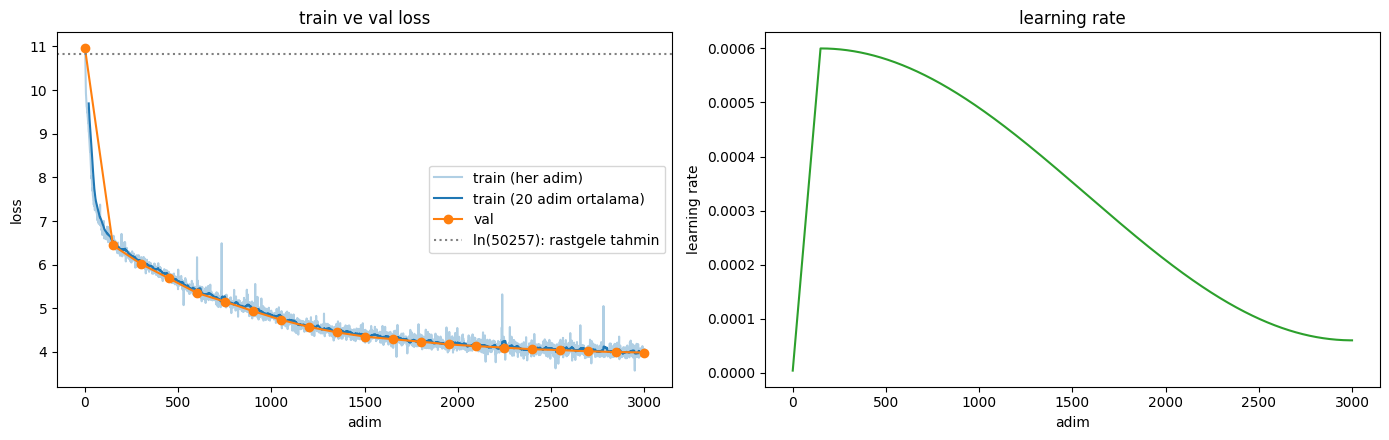

In [14]:
ms = sorted(kayit['ms'][20:]) if len(kayit['ms']) > 40 else sorted(kayit['ms'])
orta_ms = ms[len(ms) // 2]
gorulen = len(kayit['adim']) * total_batch_size
print(f'gorulen token        : {gorulen:,d}')
print(f'toplam sure          : {kayit["sure_sn"] / 60:.1f} dk')
print(f'adim suresi (ortanca): {orta_ms:.0f} ms')
print(f'token/sn (ortanca)   : {total_batch_size / (orta_ms / 1000):,.0f}')
print(f'son 20 adim train    : {sum(kayit["train"][-20:]) / len(kayit["train"][-20:]):.4f}')
print(f'son val loss         : {kayit["val"][-1]:.4f}')

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(kayit['adim'], kayit['train'], color='tab:blue', alpha=0.35, label='train (her adim)')
if len(kayit['train']) >= 20:
    tr = np.array(kayit['train'])
    ort = np.convolve(tr, np.ones(20) / 20, mode='valid')
    ax[0].plot(kayit['adim'][19:], ort, color='tab:blue', label='train (20 adim ortalama)')
ax[0].plot(kayit['val_adim'], kayit['val'], 'o-', color='tab:orange', label='val')
ax[0].axhline(math.log(50257), color='gray', ls=':', label='ln(50257): rastgele tahmin')
ax[0].set_xlabel('adim'); ax[0].set_ylabel('loss'); ax[0].set_title('train ve val loss'); ax[0].legend()
ax[1].plot(kayit['adim'], kayit['lr'], color='tab:green')
ax[1].set_xlabel('adim'); ax[1].set_ylabel('learning rate'); ax[1].set_title('learning rate')
plt.tight_layout()
plt.savefig('loss_grafigi.png', dpi=130)
plt.show()

In [ ]:
#### sonuclar: 196.608.000 token gorduk, saniyede 182.909 token (ortanca), egitim toplam 19 dakika (val ve uretim dahil).
# son 20 adimin train loss'u 4,01. son val loss 3,99.
# hafta 11'in T4 hizi ~19.000 token/sn idi, A100 yaklasik 10 kat hizli.
#
# grafik: val loss 10,95 -> 6,44 (150. adim) -> 5,16 (750) -> 4,35 (1500) -> 3,99 (3000). baslangic ln(50257) = 10,82'ye yakin, rastgele model beklendigi gibi.
# train ve val neredeyse ust uste: 4,01 ve 3,99. overfit yok. model her token'i en fazla bir kez gordu, ezberleyecek firsati olmadi.
# yani loss'u sinirlayan ezber degil, modelin henuz yeterince veri gormemis olmasi. egri sonda yataylasiyor cunku learning rate de 6e-5'e iniyor.
# train'deki tek tek sivri noktalar (2781. adim 5,05 gibi) tek bir batch'in zor olmasi. val'de boyle bir ziplama yok.

In [16]:
# egitim ilerledikce ayni baslangicin ayni seed'le urettigi metin
for i, b in enumerate(BASLANGICLAR):
    print('=' * 100)
    print('BASLANGIC:', b)
    for adim in sorted(kayit['uretim'], key=int):
        print(f'[adim {int(adim):4d}]', kayit['uretim'][adim][i].replace('\n', ' '))

BASLANGIC: Hello, I'm a language model,
[adim    0] Hello, I'm a language model,dead lied Architecture Patrezinf flawAREHTTP categianakeptggerishment Parking minimalistranchnox */ Thr Indonesia coveted coveted bearings Slip realiseoglywedprot sourcing notch Pokémon Crafting Friend preced iterationsinatesurned VI 243
[adim  500] Hello, I'm a language model, but the way to the new text as of text. All of I should use the most elaborate or in their own music in the same end of a text, with the first hand that a certain line
[adim 1000] Hello, I'm a language model, and I’m like, the fact that I’re all in the way I find in, and is the case I’m interested in the past. I’m still
[adim 1500] Hello, I'm a language model, and I would like it on your first lecture session. I am teaching students with the first lesson that is really a lot, and it's as I would seem to be a bit about you. I
[adim 2000] Hello, I'm a language model, and I'm a computer engineering teacher -- from NPR's P.D. "I don't li

In [ ]:
#### ayni baslangic, ayni seed, adim adim.
# adim 0: anlamsiz token yigini ("cryptic sleevesbrook Armantically"). rastgele model, loss 10,95.
# adim 500: kelimeler ve noktalama yerinde ama cumle kurulmuyor ("is well as it. In order is usually done because...").
# adim 1000-1500: cumleler dilbilgisel olmaya basliyor, konuyla ilgili kelimeler geliyor (Earth -> planet, atmosphere).
# adim 3000: akici, gramer dogru ama icerik yanlis. "The Earth orbits the Earth's mass of about 8 miles below the Earth's surface".
# "In mathematics, a prime number is calculated by calculating the value of all known arithmetic concepts."
# yani model dilin yuzeyini ogrendi: hangi kelime hangisinin pesinden gelir. dunyanin nasil isledigini henuz bilmiyor. HellaSwag'de de tam olarak bu goruluyor.

## task 4
HellaSwag'de ölç. HellaSwag'i önce kendi modelinde, sonra OpenAI'ın GPT-2 ağırlıklarında koş. Rastgele tahmin yüzde 25 doğru bulur. Senin modelin ne kadar buluyor, OpenAI'ın modelinden ne kadar uzakta? Aradaki farkın nereden geldiğini kendi cümlelerinle yaz. (3:28:23 - 3:56:21)

In [18]:
HS_N = None         # None: butun val seti (10.042 ornek)
# rowanz/hellaswag github reposu 2026-09'dan beri DMCA nedeniyle kapali, ayni veriyi yazarin hugging face kopyasindan aliyoruz
from datasets import load_dataset
hs = list(load_dataset('Rowan/hellaswag', split='validation'))
for ex in hs:
    ex['label'] = int(ex['label'])
print('hellaswag val:', len(hs), 'ornek')
print('baglam :', hs[0]['ctx'])
for i, son in enumerate(hs[0]['endings']):
    print(f'  {"*" if i == hs[0]["label"] else " "} {i}: {son}')

def ornek_tensor(ex):
    # her ornek 4 satir: ayni baglam + 4 farkli son. kisa satirlar 0 ile dolduruluyor
    baglam = enc.encode(ex['ctx'])
    sonlar = [enc.encode(' ' + s) for s in ex['endings']]
    L = max(len(baglam) + len(s) for s in sonlar)
    tok = torch.zeros(4, L, dtype=torch.long)
    maske = torch.zeros(4, L, dtype=torch.long)
    for i, s in enumerate(sonlar):
        satir = baglam + s
        tok[i, :len(satir)] = torch.tensor(satir)
        maske[i, len(baglam):len(satir)] = 1     # sadece son kismi puanlaniyor, baglam degil
    return tok, maske, ex['label']

@torch.no_grad()
def hellaswag_olc(m, ad):
    # autocast kapali: float16/bfloat16 yuvarlamasi sonucu etkilemesin (A100'de matris carpimi TF32)
    t0 = time.time()
    orn = hs if HS_N is None else hs[:HS_N]
    d_top, d_ort = 0, 0
    for i, ex in enumerate(orn):
        tok, maske, etiket = ornek_tensor(ex)
        tok, maske = tok.to(device), maske.to(device)
        logits, _ = m(tok)
        k = F.cross_entropy(logits[:, :-1, :].reshape(-1, logits.size(-1)), tok[:, 1:].reshape(-1), reduction='none').view(4, -1)
        mm = maske[:, 1:].float()
        top = (k * mm).sum(dim=1)                 # sonun toplam loss'u
        ort = top / mm.sum(dim=1)                 # token basina loss: uzun sonlar cezalandirilmasin
        d_top += int(top.argmin().item() == etiket)
        d_ort += int(ort.argmin().item() == etiket)
        if (i + 1) % 2500 == 0:
            print(f'  {ad}: {i + 1}/{len(orn)} | toplam {d_top / (i + 1):.4f} | token basina {d_ort / (i + 1):.4f}', flush=True)
    sonuc = dict(ad=ad, n=len(orn), dogru_toplam=d_top, dogru_ort=d_ort, acc=d_top / len(orn), acc_norm=d_ort / len(orn), sure_sn=time.time() - t0)
    print(f'{ad:18s} | n={sonuc["n"]} | toplam {sonuc["acc"]:.4f} | token basina {sonuc["acc_norm"]:.4f} | {sonuc["sure_sn"]:.0f} sn', flush=True)
    return sonuc

Generating train split:   0%|          | 0/39905 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10003 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/10042 [00:00<?, ? examples/s]

hellaswag val: 10042 ornek
baglam : A man is sitting on a roof. he
    0: is using wrap to wrap a pair of skis.
    1: is ripping level tiles off.
    2: is holding a rubik's cube.
  * 3: starts pulling up roofing on a roof.


In [ ]:
#### HellaSwag: bir baglam ve 4 olasi devam. dogru olan mantikli devam, digerleri ozellikle kandirmak icin uretilmis.
# modele soru sormuyoruz. baglam + her son icin modelin loss'unu hesapliyoruz, en az sasirdigi (loss'u en dusuk) sonu sectigini varsayiyoruz.
# maske sadece son kismi puanliyor, baglam dort satirda da ayni oldugu icin farki yaratmiyor.
# iki olcum var: toplam loss uzun sonlari cezalandiriyor, token basina loss bunu duzeltiyor. ikisini de yazdik.
# rastgele tahmin %25. butun val setini (10.042 ornek) kullandik, ilk 1.000 ile sinirlamadik.
# not: orijinal github reposu (rowanz/hellaswag) DMCA yuzunden kapali, veriyi yazarin hugging face kopyasindan (Rowan/hellaswag) aldik.
# kodun dogrulugunu OpenAI agirliklariyla kontrol ettik: 0,2860 / 0,2955 cikti, karpathy'nin betigi ayni set icin 0,2859 / 0,2955 veriyor.

In [20]:
sonuc_kendi = []
for yol in sorted(glob.glob('ckpt/model_*.pt')):
    adim = int(os.path.basename(yol).split('_')[1].split('.')[0])
    model.load_state_dict(torch.load(yol, map_location=device))
    r = hellaswag_olc(model, f'kendi model {adim}')
    r['adim'] = adim
    sonuc_kendi.append(r)
    json.dump(sonuc_kendi, open('hellaswag_kendi.json', 'w'))

  kendi model 750: 2500/10042 | toplam 0.2956 | token basina 0.2560


  kendi model 750: 5000/10042 | toplam 0.2832 | token basina 0.2562


  kendi model 750: 7500/10042 | toplam 0.2715 | token basina 0.2477


  kendi model 750: 10000/10042 | toplam 0.2589 | token basina 0.2407


kendi model 750    | n=10042 | toplam 0.2588 | token basina 0.2406 | 61 sn


  kendi model 1500: 2500/10042 | toplam 0.2960 | token basina 0.2880


... (10 outputs left out)

  kendi model 3000: 5000/10042 | toplam 0.2852 | token basina 0.2778


  kendi model 3000: 7500/10042 | toplam 0.2701 | token basina 0.2629


  kendi model 3000: 10000/10042 | toplam 0.2583 | token basina 0.2527


kendi model 3000   | n=10042 | toplam 0.2583 | token basina 0.2524 | 62 sn


In [21]:
def openai_gpt2():
    from transformers import GPT2LMHeadModel
    hf = GPT2LMHeadModel.from_pretrained('gpt2').state_dict()
    m = GPT(GPTConfig(vocab_size=50257)).to(device)
    sd = m.state_dict()
    donuk = ('attn.c_attn.weight', 'attn.c_proj.weight', 'mlp.c_fc.weight', 'mlp.c_proj.weight')
    with torch.no_grad():
        for k, v in hf.items():
            if k not in sd:
                continue
            v = v.to(device)
            sd[k].copy_(v.t() if k.endswith(donuk) else v)   # openai conv1d kullaniyor: bu dort agirlik ters duruyor
    return m

m_openai = openai_gpt2()
sonuc_openai = hellaswag_olc(m_openai, 'openai gpt2')
print('karpathy betigi ayni set icin: toplam 0.2859, token basina 0.2955')
print()
print('openai gpt2 ayni baslangiclarla:')
openai_metin = [uret(m_openai, b) for b in BASLANGICLAR]
for m in openai_metin:
    print('  >', m.replace('\n', ' '))

  openai gpt2: 2500/10042 | toplam 0.3340 | token basina 0.3408


  openai gpt2: 5000/10042 | toplam 0.3158 | token basina 0.3186


  openai gpt2: 7500/10042 | toplam 0.2977 | token basina 0.3043


  openai gpt2: 10000/10042 | toplam 0.2861 | token basina 0.2956


openai gpt2        | n=10042 | toplam 0.2860 | token basina 0.2955 | 64 sn


karpathy betigi ayni set icin: toplam 0.2859, token basina 0.2955

openai gpt2 ayni baslangiclarla:


  > Hello, I'm a language model, and I like to be able to describe ideas better than I can tell anyone else. And yes, there's a reason for that, but it is because languages are made up of hundreds of thousands of
  > The Earth orbits the Sun, where the sun takes about 8° between the Earth's edge and the Sun. Astronomers believe the Earth's poles are the closest points in the universe to the Sun, though we don't
  > In mathematics, a prime number is a number (or, better yet, binary number) that can be multiplied and decremented by another integer such as n or n^2 . The basic type of a prime number is N : (


model                    toplam  token basina
rastgele                 0.2500        0.2500
kendi model 750          0.2588        0.2406
kendi model 1500         0.2609        0.2530
kendi model 2250         0.2602        0.2493
kendi model 3000         0.2583        0.2524
openai gpt2              0.2860        0.2955

fark (openai - kendi): toplam +0.0277 | token basina +0.0430


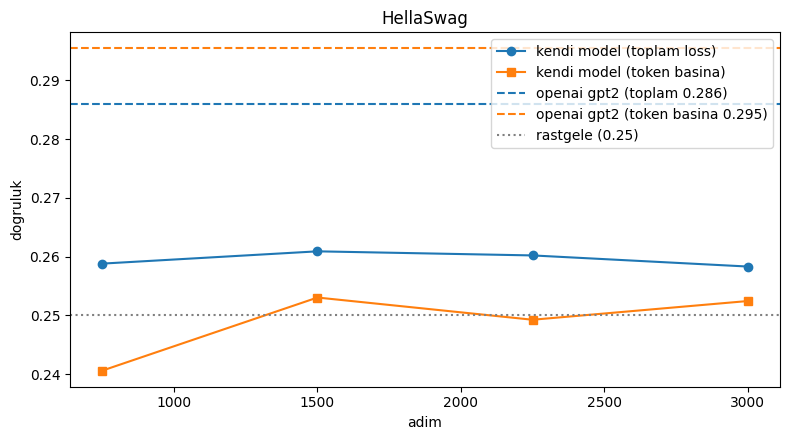

In [22]:
son = sonuc_kendi[-1]
print(f'{"model":22s} {"toplam":>8s} {"token basina":>13s}')
print(f'{"rastgele":22s} {0.25:8.4f} {0.25:13.4f}')
for r in sonuc_kendi:
    print(f'{r["ad"]:22s} {r["acc"]:8.4f} {r["acc_norm"]:13.4f}')
print(f'{sonuc_openai["ad"]:22s} {sonuc_openai["acc"]:8.4f} {sonuc_openai["acc_norm"]:13.4f}')
print()
print(f'fark (openai - kendi): toplam {sonuc_openai["acc"] - son["acc"]:+.4f} | token basina {sonuc_openai["acc_norm"] - son["acc_norm"]:+.4f}')

plt.figure(figsize=(8, 4.5))
adimlar = [r['adim'] for r in sonuc_kendi]
plt.plot(adimlar, [r['acc'] for r in sonuc_kendi], 'o-', label='kendi model (toplam loss)')
plt.plot(adimlar, [r['acc_norm'] for r in sonuc_kendi], 's-', label='kendi model (token basina)')
plt.axhline(sonuc_openai['acc'], color='tab:blue', ls='--', label=f'openai gpt2 (toplam {sonuc_openai["acc"]:.3f})')
plt.axhline(sonuc_openai['acc_norm'], color='tab:orange', ls='--', label=f'openai gpt2 (token basina {sonuc_openai["acc_norm"]:.3f})')
plt.axhline(0.25, color='gray', ls=':', label='rastgele (0.25)')
plt.xlabel('adim'); plt.ylabel('dogruluk'); plt.title('HellaSwag'); plt.legend()
plt.tight_layout()
plt.savefig('hellaswag_grafigi.png', dpi=130)
plt.show()

sonuclar = dict(
    gorulen_token=len(kayit['adim']) * total_batch_size, max_steps=MAX_STEPS, batch=total_batch_size,
    sure_dk=kayit['sure_sn'] / 60, ortanca_ms=orta_ms, token_sn=total_batch_size / (orta_ms / 1000),
    son_val=kayit['val'][-1], son_train20=float(np.mean(kayit['train'][-20:])),
    hellaswag_kendi=sonuc_kendi, hellaswag_openai=sonuc_openai, openai_metin=openai_metin,
)
json.dump(sonuclar, open('sonuclar.json', 'w'), indent=2)

In [ ]:
#### sonuc. 10.042 ornekte:
#   kendi model (3000. adim): toplam %25,83 | token basina %25,24
#   OpenAI GPT-2            : toplam %28,60 | token basina %29,55
#   rastgele                : %25
# OpenAI'dan uzaklik: toplamda 2,8 puan, token basinda 4,3 puan.
#
# %25'ten farki gercek mi: 10.042 ornekte tesadufi oynama yaklasik arti eksi 0,85 puan (%95 aralik). 25,83 ve 25,24 bu aralikta.
# yani kendi modelimiz HellaSwag'de rastgele tahminden ayirt edilemiyor. OpenAI'nin 28,6 ve 29,55'i ise aralik disinda, gercekten bir sey biliyor.
#
# ilginc olan: 750. adimdan sonra val loss 5,16'dan 3,99'a indi ama HellaSwag neredeyse kipirdamadi: toplamda %25,88 -> %25,83, token basina %24,06 -> %25,24.
# token basina ilk basta rastgelenin altindaydi, %25 seviyesine cikti ama ustune gecemedi.
# loss hizli dustu cunku ilk kazanilan sey kelime sikligi ve dilbilgisi. HellaSwag'in sectigi yanlis sonlar da dilbilgisi olarak duzgun, ayirmak icin olayin mantigini bilmek lazim.
#
# fark nereden geliyor:
#   1) gorulen veri. biz 197 milyon token gorduk, karpathy'nin videodaki egitimi 10 milyar token, yani bizimkinin 50 kati. bizim egitim onun %2'si kadar.
#      train ve val ayni oldugu icin model ezber yapmiyor, sadece az veri gormus: daha cok veri daha iyi sonuc verir.
#   2) uretilen metin de bunu gosteriyor: gramer tamam, "The Earth orbits the Earth's mass" gibi anlam yanlis. HellaSwag tam bu ayrimi olcuyor.
#   3) veri turu da etkili olabilir: FineWeb-Edu egitici metin, HellaSwag ise gunluk etkinlik ve nasil-yapilir anlatimlari. bunu ayrica olcmedik.
#   ayni test, ayni kod, ayni mimari: geriye kalan fark egitim miktari ve veri.

In [ ]:
#### ozet
# - veri: FineWeb-Edu'dan 199.000 dokuman, 210 milyon token, 21 dosya (1 val + 20 train).
# - egitim: 124M parametreli GPT-2, A100, 196,6 milyon token, 19 dakika, saniyede ~183.000 token.
# - loss: val 10,95 -> 3,99, son train 4,01. train ve val ust uste, overfit yok.
# - metin: anlamsiz token'lardan dilbilgisi dogru ama anlamca yanlis cumlelere geldi.
# - HellaSwag (10.042 ornek): kendi model %25,83 / %25,24, OpenAI %28,60 / %29,55, rastgele %25. kendi modelimiz rastgeleden ayirt edilemiyor.
# - loss'un dusmesi "anladi" demek degil: 750. adimdan sonra val loss 5,16'dan 3,99'a indi, HellaSwag %25 civarinda kaldi.
# - ek gorev (turkce egitim) yapilmadi.